#LLM - Klasyczne metody klasyfikacji tekstu - LAB

#Zadanie

Zaadaptuj kod z notatnika *LLM - Klasyczne metody klasyfikacji tekstu - Omówienie* do problemu klasyfikacji liczby gwiazdek dla opinii z serwisu Yelp.
Możesz przygotować pętlę treningową albo w czystym PyTorchu, albo z wykorzystaniem biblioteki PyTorch Lightning.

* Wykorzystaj zbiór `Yelp/yelp_review_full` ([link](https://huggingface.co/datasets/Yelp/yelp_review_full)) zawierający opinie z serwisu Yelp (kolumna: `text`) i etykietę (kolumna: `label`) o wartościach $0,1,2,3,4$ określającą liczbę gwiazdek przyznaną przez użytkownika (a ściślej, liczbę gwiazdek minus jeden). Ponieważ mamy pięć klas, ostatnia warstwa liniowa w sieci neuronowej musi zwracać pięć wartości.
    * Zgodnie z dobrą praktyką z części treningowej wydziel dodatkową część walidacyjną i testową.
    * Ogranicz rozmiar każdej części zbioru danych (treningowej, walidacyjnej i testowej). Część treningowa nie powinna zawierać więcej niż 100k elementów.
* Do ekstrakcji cech z tekstu wykorzystaj **metodę TF-IDF** (*term frequency-inverse document frequency*) opartą o podejście typu worek słów (*bag-of-words*). Zastosuj funkcję `TfidfVectorizer` z biblioteki `scikit-learn`.
* Wykorzystaj podobną architekturę sieci (perceptron wielowarstwowy z warstwą Dropout) jak w notatniku wykładowym.



## Punkty do wykonania

1.   Napisz funkcję znajdującą i wyświetlającą $k$ elementów zbioru testowego dla których model najbardziej się myli, czyli estymuje najmniejsze prawdopodobieństwa prawdziwej klasy. Softmax jest funkcją ściśle rosnącą, więc wystarczy znaleźć elementy z najmniejszą wartością nieznormalizowanego wyjścia z sieci (logita) dla prawdziwej klasy.
2.   Zbadaj wpływ wybranych parametrów funkcji ekstrakcji cech z tekstu `TfidfVectorizer` na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami parametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym.
3.   Zbadaj wpływ wybranych hiperparametrów modelu (np. liczba warstw liniowych modelu, rozmiary warstw) i procesu uczenia (np. początkowa wartość stopy uczenia, liczba epok, typ i parametry planisty stopy uczenia, typ i parametry optymalizatora) na skuteczność wytrenowanego modelu. Uruchom kilka eksperymentów z różnymi wartościami hiperparametrów i porównaj dokładność wytrenowanego modelu na zbiorze walidacyjnym. Następnie wykonaj finalną ewaluację najlepszego modelu na zbiorze testowym.


##Przygotowanie środowiska
Upewnij się, że notatnik jest uruchomiony na maszynie z GPU. Jesli GPU nie jest dostępne zmień typ maszyny (Runtime | Change runtime type) i wybierz T4 GPU.

In [1]:
# !nvidia-smi

Instalacja dodatkowych bibliotek: datasets (z biblioteki HuggingFace), TorchMetrics i W&B (Weights and Biases) Models.

In [2]:
!pip install -q datasets
!pip install -q torchmetrics
!pip install -q wandb

Import bibliotek.

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt

print(f"Wersja biblioteki PyTorch: {torch.__version__}")

Wersja biblioteki PyTorch: 2.10.0


Sprawdzenie dostępności GPU.

In [4]:
print(f"Dostępność GPU CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Typ GPU: {torch.cuda.get_device_name(0)}")

print(f"Dostępność GPU MPS: {torch.mps.is_available()}")

Dostępność GPU CUDA: False
Dostępność GPU MPS: True


In [5]:
# import wandb

# # Logowanie do serwisu Weights&Biases monitorującego przebieg eksperymentów
# wandb.login()

# Solution

## Data processing and analyzation

In [6]:
from datasets import load_dataset


dataset = load_dataset("Yelp/yelp_review_full")

test_dataset = dataset["test"]
train_val_dataset = dataset["train"].train_test_split(test_size=0.2)
train_dataset = train_val_dataset["train"]
val_dataset = train_val_dataset["test"]

print(train_dataset.shape)
print(val_dataset.shape)
print(test_dataset.shape)

train_dataset = train_dataset.shuffle(seed=42).select(range(int(len(train_dataset)*0.15)))
val_dataset = val_dataset.shuffle(seed=42).select(range(int(len(val_dataset)*0.15)))
test_dataset = test_dataset.shuffle(seed=42).select(range(int(len(test_dataset)*0.15)))

print(f"Liczba próbek w zbiorze treningowym: {len(train_dataset)}")
print(f"Liczba próbek w zbiorze walidacyjnym: {len(val_dataset)}")
print(f"Liczba próbek w zbiorze testowym: {len(test_dataset)}")

(520000, 2)
(130000, 2)
(50000, 2)
Liczba próbek w zbiorze treningowym: 78000
Liczba próbek w zbiorze walidacyjnym: 19500
Liczba próbek w zbiorze testowym: 7500


In [7]:
id = int(np.random.choice(range(len(train_dataset))))
print(f"Row={id}")
sample = train_dataset[id]
print(f"{sample['text']=}")
print(f"{sample['label']=}")

Row=35292
sample['text']='Ok so the burger I had was called Average Joe, but let me tell you nothing is average about this burger.... They have fancy cheese fries-Delicious!!! \\nI have passed this place a million times and said look at those idiots sitting outside.... What is that place? Well I am glad to say I too am now a BrGr idiot'
sample['label']=4


Unique labels: [0 1 2 3 4], Number of unique labels: 5



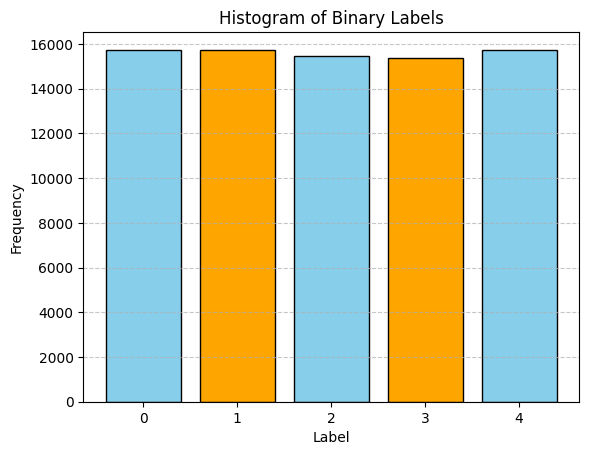

In [8]:
# Count occurrences of each label
unique_labels, counts = np.unique(train_dataset['label'], return_counts=True)
labels_num = len(unique_labels)
print(f"Unique labels: {unique_labels}, Number of unique labels: {labels_num}\n")

# Plot histogram
plt.bar(unique_labels, counts, color=['skyblue', 'orange'], edgecolor='black')
plt.title('Histogram of Binary Labels')
plt.xlabel('Label')
plt.ylabel('Frequency')
plt.xticks(unique_labels)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [10]:
vocab_size = 1000

vectorizer = TfidfVectorizer(
    max_features=vocab_size,
    lowercase=True,
    analyzer="word",
    ngram_range=(1, 1),
    stop_words="english"
)

train_features = vectorizer.fit_transform(train_dataset["text"])

val_features = vectorizer.transform(val_dataset["text"])
test_features = vectorizer.transform(test_dataset["text"])

In [11]:
print(f"TF-IDF Matric size for train dataset: {train_features.shape}")   # 78 000 rows - number of documents in (language) corpus, 1 000 columns - number of word features with weights
print(f"{train_features.dtype=}\n")

feature_names = vectorizer.get_feature_names_out()
print(f"Extracted features number: {len(feature_names)}")
print(f"Sample features: {np.random.choice(feature_names, 30)}\n")

TF-IDF Matric size for train dataset: (78000, 1000)
train_features.dtype=dtype('float64')

Extracted features number: 1000
Sample features: ['products' 'wow' 'happened' 'expectations' 'tastes' 'flight' 'prepared'
 'eating' 'hell' 'charge' 'open' 'pasta' 'tickets' 'cooked' 'vegas'
 'treated' 'nails' 'standing' 'away' 'doing' 'knows' 'portion' 'weren'
 'combo' 'incredibly' 'basic' 'bathroom' 'type' 'downtown' 'previous']



In [12]:
ndx = int(np.random.choice(range(len(train_dataset))))
print(f"Train dataset element with index={ndx}")
print(f"{train_dataset['text'][ndx]=}\n")

features = train_features[ndx]  # features extracted from document of `ndx` index out of 78 000 documents in language corpus
print(f"No-filtered features: {features}\n")  # Compressed Sparse Row sparse matrix ... shape (1, 1000) -> each feature is addressed like (0, 356)

print(f"Features of element with index={ndx}:")
non_zero_cols = features.nonzero()[1]

non_zero_cols = sorted(non_zero_cols)
for i in non_zero_cols:
    print(f"Column: {i} ({feature_names[i]})   Weight: {features[0, i]:.5f}") # coords od each feature in row/document is (0, <column_numb>)

Train dataset element with index=48006
train_dataset['text'][ndx]='So disappointed!!! I came here in 2006 and had arguably one of the best seafood meals in my life. Everything was so good! Sad to say, I went back in 2012 and had the worst meal I\'ve ever had in Vegas, and that\'s saying a lot because I\'ve eaten in a lot of shady places. Worst martini ever! Seriously it tasted like the pool. My beer was equally disgusting. Someone needs to tell the waitress the cleanser they use on the glasses is way too strong. Got roasted corn clam chowder and would have guessed it was canned corn if it weren\'t for the boatloads of silk in it! Not to mention it was probably made the week previous. Oysters were small and chewy, To top it all off, the signature grill dish came with the spicy tomato diablo sauce instead of the brandy cream sauce. Don\'t get me wrong, I like spicy food but if I order something I expect to get what I paid for. It\'s probably better that i didn\'t eat it because the cook 

Mean of non-zero features in samples: 32.41


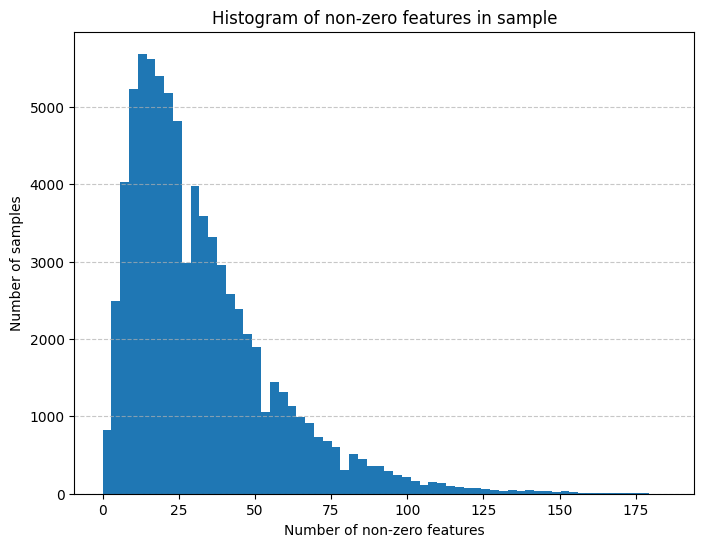

In [13]:
non_zero_counts = np.diff(train_features.indptr)
print(f"Mean of non-zero features in samples: {non_zero_counts.mean():.2f}")  # średnia liczba cech wyodrębnionych per dokument z korpusu językowego (średnia wartość dla 1 z 67 200)

# Plot histogram
plt.figure(figsize=(8, 6))
plt.hist(non_zero_counts, bins=64)
plt.title('Histogram of non-zero features in sample')
plt.xlabel('Number of non-zero features')
plt.ylabel('Number of samples')
plt.grid(axis='y', linestyle='--', alpha=0.7)

In [14]:
import torch

from torch.utils.data import TensorDataset, DataLoader

In [15]:
def make_dataset(sparse_features, labels):
    dense_features = sparse_features.astype(np.float32).todense()     # scipy.sparse.spmatrix.todense() --> numpy.matrix
    dataset = TensorDataset(
        torch.from_numpy(dense_features),
        torch.tensor(labels, dtype=torch.int64)
    )
    return dataset


# print(type(train_features))           # type: scipy.sparse._csr.csr_matrix
# print(type(train_dataset['label']))   # type: datasets.arrow_dataset.Column

datasets = {
    'train': make_dataset(train_features, train_dataset['label']),
    'val': make_dataset(val_features, val_dataset['label']),
    'test': make_dataset(test_features, test_dataset['label'])
}

print(datasets['train'][0])

(tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.4486, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.2915, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000,

In [16]:
batch_size = 128

data_loaders = {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}

In [17]:
for X_batch, y_batch in data_loaders['train']:
    print(f"{X_batch.shape=}")
    print(f"{y_batch.shape=}")
    break

X_batch.shape=torch.Size([128, 1000])
y_batch.shape=torch.Size([128])


## Stage 0 - basic model + train loop + helper functions definion

In [18]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
print(f"Device: {device}")

Device: mps


In [19]:
import torch.nn as nn


class RatingClassifier(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 64),
            nn.LeakyReLU(),
            nn.Linear(64, 128),
            nn.LeakyReLU(),
            nn.Linear(128, 32),
            nn.LeakyReLU(),
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(32, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits

#### Model Training loop

In [20]:
import torch.nn as nn
import torchmetrics
from tqdm import tqdm


def train(model: nn.Module, loaders: dict[DataLoader], criterion: nn.Module,
          optimizer: torch.optim.Optimizer, lr_scheduler, num_epochs: int):

    accumulated_loss = []
    accumulated_acc = []

    metric_loss = torchmetrics.aggregation.MeanMetric().to(device)
    metric_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=labels_num).to(device)

    # val_loss = np.array(np.inf)
    # overfitting_counter = 0

    for epoch in range(1, num_epochs+1):

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            for X_batch, target in tqdm(loaders[phase]):

                X_batch, target = X_batch.to(device), target.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    logits = model(X_batch)
                    # dim=1, as columns (dim=1) are 'squeezed' to one max value
                    _, preds = torch.max(logits, dim=1)   # torch.max() --> [values, indices] - pred is index of max value as in softmax highest value will have highest prob as well
                    loss = criterion(logits, target)

                    metric_loss(loss)
                    metric_acc(preds, target)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

            acc = metric_acc.compute()
            mean_loss = metric_loss.compute()
            current_lr = lr_scheduler.get_last_lr()[0]

            # if phase == "val":
            #     if mean_loss.to_numpy() > val_loss:
            #         overfitting_counter += 1
            #     else:
            #         val_loss = mean_loss.to_numpy()

            print(f"(Epoch {epoch}/[{phase}]) Loss:\t{mean_loss:.3f}   Accuracy: {acc:.3f}   lr: {current_lr}")
            metrics = {
                f"{phase}/loss": mean_loss,
                f"{phase}/accuracy": acc,
                f"{phase}/lr": current_lr,
            }
            # wandb.log(metrics, step=epoch)

            if phase == "val":
                accumulated_loss.append(float(mean_loss.cpu()))
                accumulated_acc.append(float(acc.cpu()))

            metric_loss.reset()
            metric_acc.reset()

            # if overfitting_counter > 5:
            #     break

        lr_scheduler.step()

    return accumulated_loss, accumulated_acc


In [21]:
def find_worst_predictions(logits: torch.Tensor, targets: torch.Tensor, k=5):
    logit_per_true_class = logits.gather(dim=1, index=targets.view(-1, 1)).squeeze(1)
    values, indices = torch.topk(logit_per_true_class, k=k, largest=False)
    return values, indices

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


def plot_confusion_matrix(targets, preds):
    cm = confusion_matrix(targets, preds, normalize="true")
    plt.figure(figsize=(10, 8))
    classes = list(range(labels_num))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', 
                xticklabels=classes, yticklabels=classes)
    plt.xlabel("Prediction")
    plt.ylabel("True class")
    plt.title("Confussion matrix")
    plt.show()



In [23]:
def plot_comparison(metric_dict, title, ylabel):
    sns.set_theme(style="whitegrid")
    
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=False)

    for model_name, metrics_val in metric_dict.items():
        epochs = range(1, len(metrics_val) + 1)
        plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.7)

    fig.subplots_adjust(right=0.72)

    leg = ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=True,
        title="Experiment legend",
        borderaxespad=0.0
    )
    leg.get_frame().set_alpha(1.0)

    plt.show()

## Stage 1 - simple test model training + finding `k` worst preds for true class

In [24]:
classifier = RatingClassifier(vocab_size, n_classes=labels_num)
classifier.to(device)

print(classifier)

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=1000, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


In [25]:
num_epochs = 30

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)

In [26]:
# run = wandb.init(project="MyExperiments")

_, _ = train(classifier, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)

# run.finish()

100%|██████████| 610/610 [00:02<00:00, 206.45it/s]


(Epoch 1/[train]) Loss:	1.443   Accuracy: 0.347   lr: 0.0001


100%|██████████| 153/153 [00:00<00:00, 287.58it/s]


(Epoch 1/[val]) Loss:	1.185   Accuracy: 0.470   lr: 0.0001


100%|██████████| 610/610 [00:02<00:00, 240.76it/s]


...

(Epoch 29/[val]) Loss:	1.050   Accuracy: 0.540   lr: 1.0983357966978745e-05


100%|██████████| 610/610 [00:03<00:00, 180.58it/s]


(Epoch 30/[train]) Loss:	1.029   Accuracy: 0.555   lr: 1.0246514708427697e-05


100%|██████████| 153/153 [00:00<00:00, 299.57it/s]

(Epoch 30/[val]) Loss:	1.050   Accuracy: 0.541   lr: 1.0246514708427697e-05


In [27]:
logits_l = []
preds_l = []
targets_l = []
input_l = []

classifier.eval()
with torch.inference_mode():
    for X_batch, target in tqdm(data_loaders['test']):
        X_batch, target = X_batch.to(device), target.to(device)
        logits = classifier(X_batch)
        _, preds = torch.max(logits, dim=-1)
        preds_l.append(preds.cpu())
        logits_l.append(logits.cpu())
        targets_l.append(target.cpu())
        input_l.append(X_batch.cpu())

all_logits = torch.cat(logits_l, dim=0)
all_preds = torch.cat(preds_l, dim=0)
all_targets = torch.cat(targets_l, dim=0)
all_input = torch.cat(input_l, dim=0)

find_worst_predictions(all_logits, all_targets)

100%|██████████| 59/59 [00:00<00:00, 503.74it/s]


(tensor([-4.3416, -4.3062, -3.7970, -3.1467, -2.7977]),
 tensor([5240, 1710, 6155, 2761, 5740]))

## Stage 2 - finding best Vectorizer params

In [28]:
from dataclasses import dataclass, asdict


@dataclass
class VectorizerParams:
      max_features: int
      lowercase: bool
      analyzer: str
      ngram_range: tuple[int, int]
      stop_words: str = "english"



def prep_dataloaders(params: VectorizerParams, datasets: list, batch_size: int = 128):

    vectorizer = TfidfVectorizer(**asdict(params))

    train_dataset, val_dataset, test_dataset = datasets

    train_features = vectorizer.fit_transform(train_dataset["text"])

    val_features = vectorizer.transform(val_dataset["text"])
    test_features = vectorizer.transform(test_dataset["text"])


    datasets = {
        'train': make_dataset(train_features, train_dataset['label']),
        'val': make_dataset(val_features, val_dataset['label']),
        'test': make_dataset(test_features, test_dataset['label'])
    }

    batch_size = 256

    return {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}


In [29]:
vectorizers = [
    VectorizerParams(max_features=100, lowercase=True, analyzer="word", ngram_range=(1, 1)),
    VectorizerParams(max_features=1000, lowercase=False, analyzer="word", ngram_range=(1, 2)),
    VectorizerParams(max_features=1000, lowercase=True, analyzer="word", ngram_range=(2, 2)),
    VectorizerParams(max_features=10000, lowercase=True, analyzer="word", ngram_range=(1, 1)),
    VectorizerParams(max_features=10000, lowercase=True, analyzer="word", ngram_range=(1, 3))
]

In [30]:
all_tested_losses = {}
all_tested_acc = {}

plain_datasets = (train_dataset, val_dataset, test_dataset)
num_epochs = 10

for vectorizer in vectorizers:
    classifier = RatingClassifier(vectorizer.max_features, n_classes=labels_num)
    classifier.to(device)

    print(classifier)
    print(f"{vectorizer}\n")

    data_loaders = prep_dataloaders(vectorizer, plain_datasets)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)
    lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)


    accumulated_loss, accumulated_acc = train(classifier, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
    all_tested_losses[str(vectorizer)] = accumulated_loss
    all_tested_acc[str(vectorizer)] = accumulated_acc


RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=100, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)
VectorizerParams(max_features=100, lowercase=True, analyzer='word', ngram_range=(1, 1), stop_words='english')



100%|██████████| 305/305 [00:01<00:00, 172.98it/s]


(Epoch 1/[train]) Loss:	1.603   Accuracy: 0.223   lr: 0.0001


100%|██████████| 77/77 [00:00<00:00, 270.98it/s]


(Epoch 1/[val]) Loss:	1.567   Accuracy: 0.358   lr: 0.0001


...

(Epoch 9/[val]) Loss:	0.956   Accuracy: 0.580   lr: 1.8594235253127375e-05


100%|██████████| 305/305 [00:02<00:00, 123.91it/s]


(Epoch 10/[train]) Loss:	0.864   Accuracy: 0.627   lr: 1.2202456766718093e-05


100%|██████████| 77/77 [00:00<00:00, 128.13it/s]

(Epoch 10/[val]) Loss:	0.956   Accuracy: 0.580   lr: 1.2202456766718093e-05


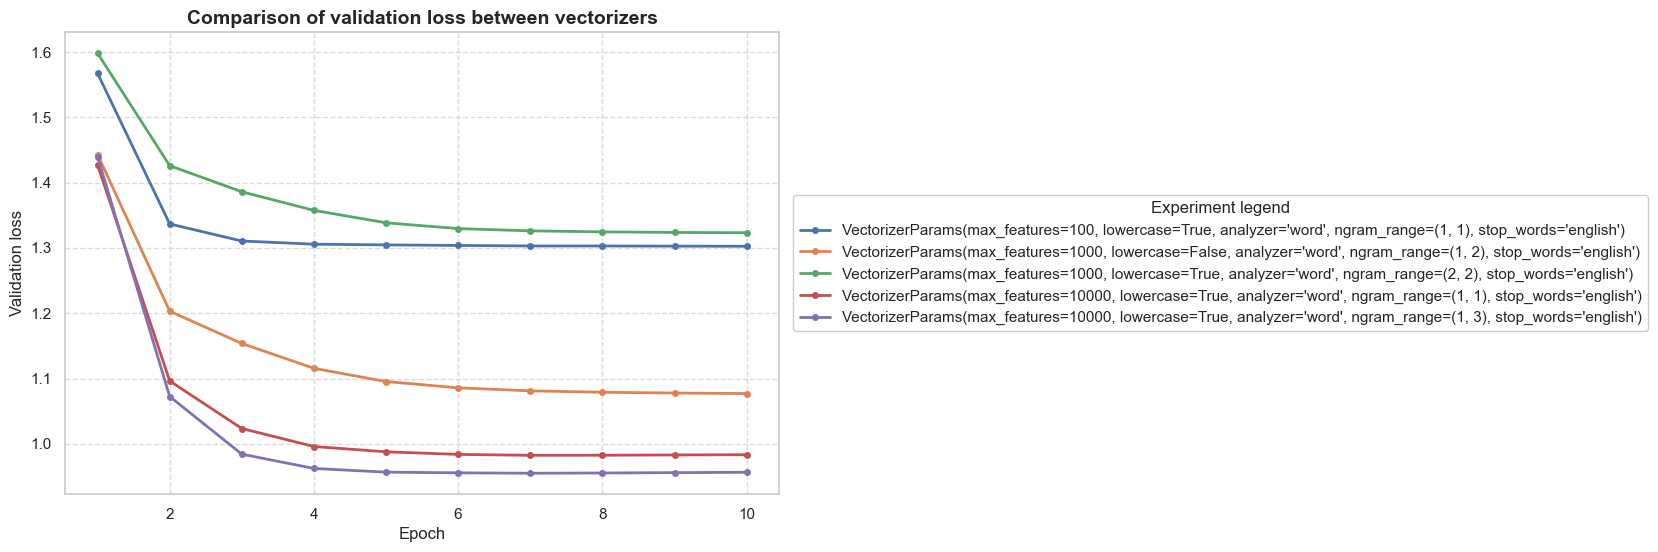

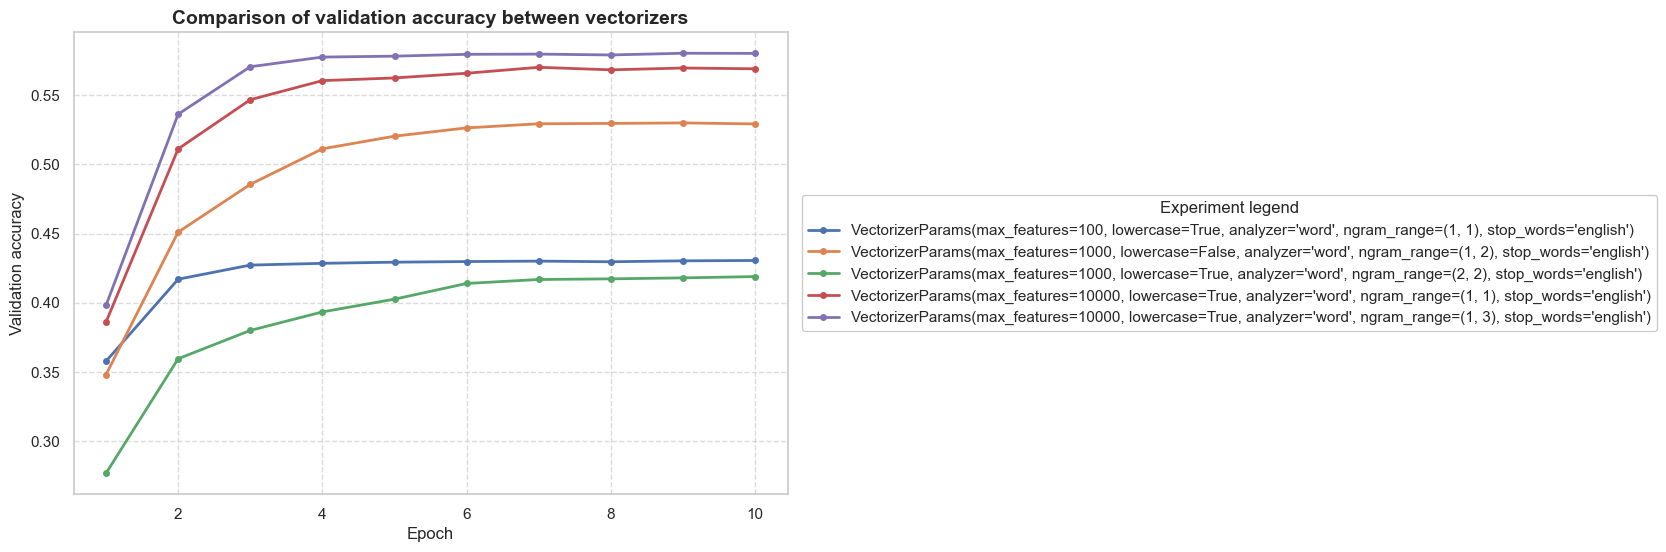

In [31]:
plot_comparison(all_tested_losses, title="Comparison of validation loss between vectorizers", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy between vectorizers", ylabel="Validation accuracy")

#### Training + Evaluation on test dataset for data transformed by best found vectorizer 

In [32]:
vectorizer = VectorizerParams(max_features=10000, lowercase=True, analyzer="word", ngram_range=(1, 3))

classifier = RatingClassifier(vectorizer.max_features, n_classes=labels_num)
classifier.to(device)

print(classifier)

data_loaders = prep_dataloaders(vectorizer, plain_datasets)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)


_, _ = train(classifier, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


100%|██████████| 305/305 [00:03<00:00, 88.81it/s]


(Epoch 1/[train]) Loss:	1.572   Accuracy: 0.252   lr: 0.0001


100%|██████████| 77/77 [00:00<00:00, 115.75it/s]


(Epoch 1/[val]) Loss:	1.415   Accuracy: 0.351   lr: 0.0001


...

(Epoch 9/[val]) Loss:	0.960   Accuracy: 0.579   lr: 1.8594235253127375e-05


100%|██████████| 305/305 [00:02<00:00, 130.81it/s]


(Epoch 10/[train]) Loss:	0.872   Accuracy: 0.621   lr: 1.2202456766718093e-05


100%|██████████| 77/77 [00:00<00:00, 200.97it/s]

(Epoch 10/[val]) Loss:	0.960   Accuracy: 0.578   lr: 1.2202456766718093e-05


100%|██████████| 30/30 [00:00<00:00, 114.47it/s]


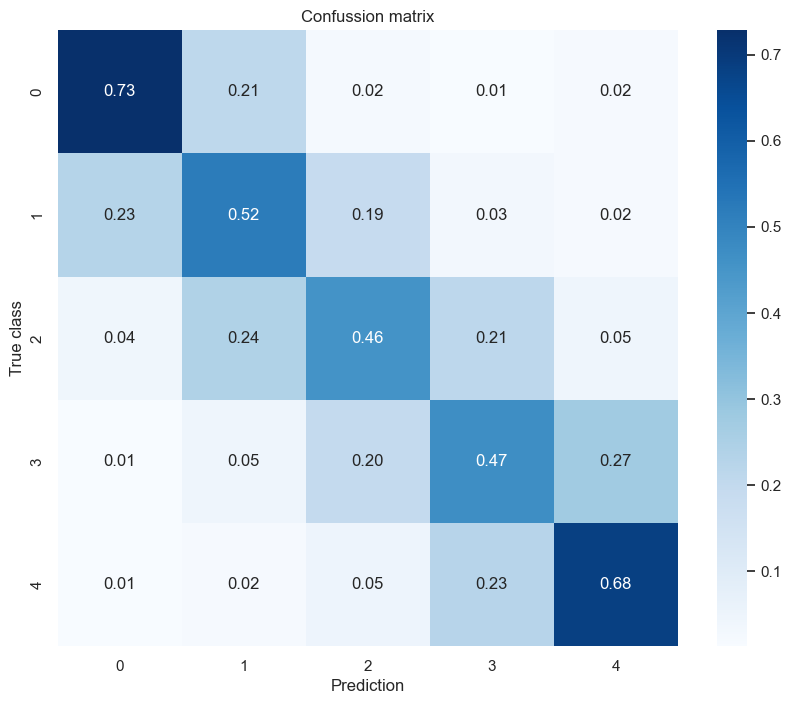

In [33]:
logits_l = []
preds_l = []
targets_l = []
input_l = []

classifier.eval()
with torch.inference_mode():
    for X_batch, target in tqdm(data_loaders['test']):
        X_batch, target = X_batch.to(device), target.to(device)
        logits = classifier(X_batch)
        _, preds = torch.max(logits, dim=-1)
        preds_l.append(preds.cpu())
        logits_l.append(logits.cpu())
        targets_l.append(target.cpu())
        input_l.append(X_batch.cpu())

all_logits = torch.cat(logits_l, dim=0)
all_preds = torch.cat(preds_l, dim=0)
all_targets = torch.cat(targets_l, dim=0)
all_input = torch.cat(input_l, dim=0)

plot_confusion_matrix(all_targets.numpy(), all_preds.numpy())

## Stage 3 - finding best model hiperparams and training stage params

#### New test models with different varianions of neurons number (hidden layers size) and hidden layers number

In [34]:
import torch.nn as nn


class RatingClassifierExtendedV1(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 32),
            nn.LeakyReLU(),
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(32, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits
    

class RatingClassifierExtendedV2(nn.Module):
    def __init__(self, vocab_size: int, n_classes: int):
        super().__init__()
        self.vocab_size = vocab_size
        self.n_classes = n_classes

        self.feature_extractor = nn.Sequential(
            nn.Linear(self.vocab_size, 256),
            nn.LeakyReLU(),
            nn.Linear(256, 128),
            nn.LeakyReLU(),
            nn.Linear(128, 64),
            nn.LeakyReLU(),
            nn.Linear(64, 32),
            nn.LeakyReLU(),
            nn.Linear(32, 16),
            nn.LeakyReLU(),
        )
        self.dropout = nn.Dropout(0.1)
        self.linear = nn.Linear(16, n_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        features = self.dropout(features)
        logits = self.linear(features)
        return logits


#### Using vectorizer with best results in stage 2 

In [35]:
vocab_size = 10000

vectorizer = TfidfVectorizer(
    max_features=vocab_size,
    lowercase=True,
    analyzer="word",
    ngram_range=(1, 3),
    stop_words="english"
)

train_features = vectorizer.fit_transform(train_dataset["text"])

val_features = vectorizer.transform(val_dataset["text"])
test_features = vectorizer.transform(test_dataset["text"])


datasets = {
    'train': make_dataset(train_features, train_dataset['label']),
    'val': make_dataset(val_features, val_dataset['label']),
    'test': make_dataset(test_features, test_dataset['label'])
}

batch_size = 256

data_loaders = {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}

#### Find best model architecture

RatingClassifier(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=32, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=32, out_features=5, bias=True)
)


100%|██████████| 305/305 [00:03<00:00, 82.88it/s]


(Epoch 1/[train]) Loss:	1.559   Accuracy: 0.306   lr: 0.0001


100%|██████████| 77/77 [00:00<00:00, 126.28it/s]


(Epoch 1/[val]) Loss:	1.344   Accuracy: 0.416   lr: 0.0001


...

(Epoch 9/[val]) Loss:	0.986   Accuracy: 0.573   lr: 1.8594235253127375e-05


100%|██████████| 305/305 [00:03<00:00, 94.71it/s]


(Epoch 10/[train]) Loss:	0.837   Accuracy: 0.643   lr: 1.2202456766718093e-05


100%|██████████| 77/77 [00:00<00:00, 137.43it/s]


(Epoch 10/[val]) Loss:	0.989   Accuracy: 0.573   lr: 1.2202456766718093e-05


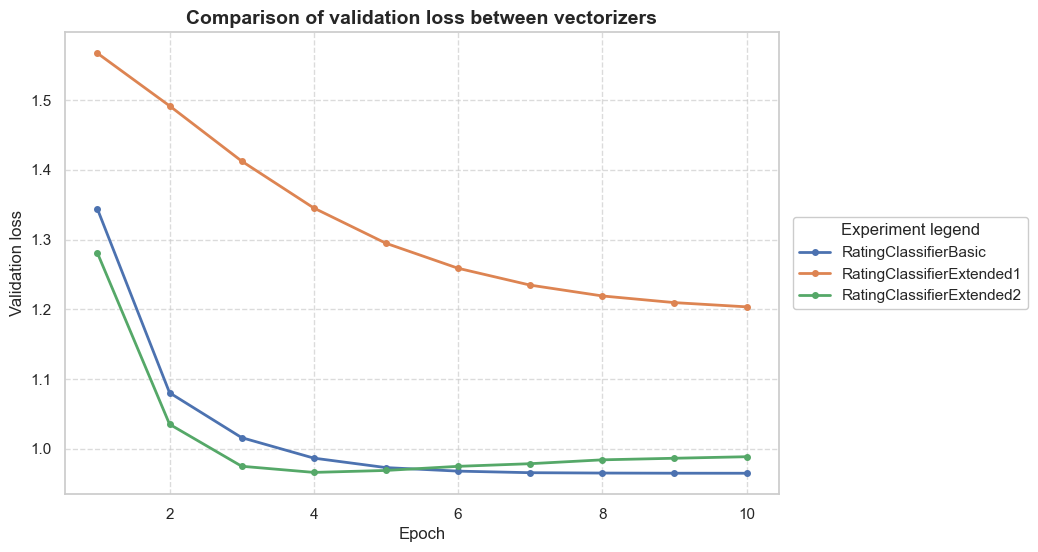

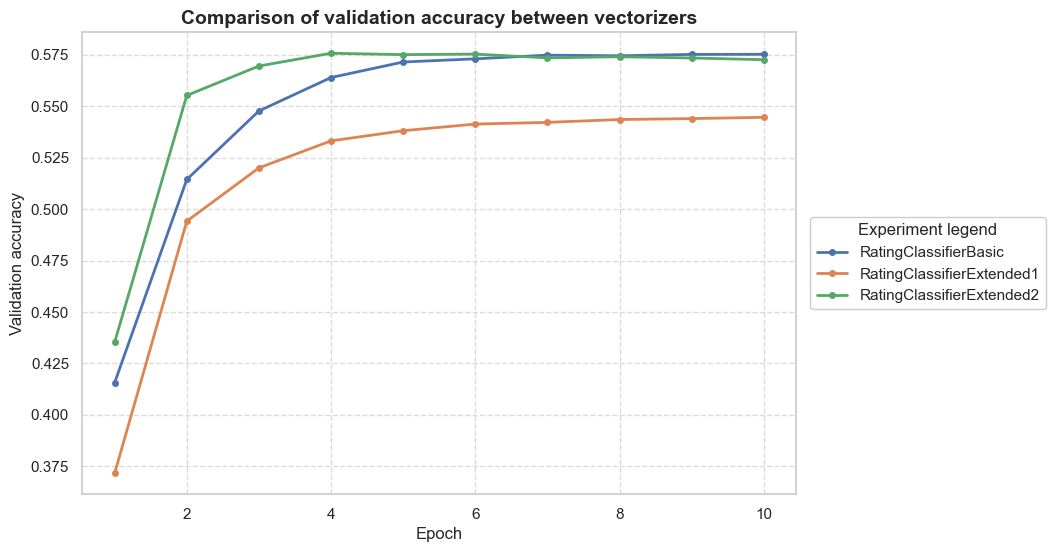

In [36]:
models = {
    "RatingClassifierBasic": RatingClassifier(vocab_size, labels_num),
    "RatingClassifierExtended1": RatingClassifierExtendedV1(vocab_size, labels_num),
    "RatingClassifierExtended2": RatingClassifierExtendedV2(vocab_size, labels_num),
}

all_tested_losses = {}
all_tested_acc = {}


num_epochs = 10

for model_alias, model in models.items():
    
    model.to(device)
    print(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)


    accumulated_loss, accumulated_acc = train(model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
    all_tested_losses[model_alias] = accumulated_loss
    all_tested_acc[model_alias] = accumulated_acc


plot_comparison(all_tested_losses, title="Comparison of validation loss between vectorizers", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy between vectorizers", ylabel="Validation accuracy")


#### Find best model hiperparams and training stage params

Testing:

RatingClassifierExtendedV2(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 5e-05
    lr: 1.6666666666666667e-05
    maximize: False
    weight_decay: 1e-05
)
('linearLR'

100%|██████████| 305/305 [00:03<00:00, 90.82it/s]


(Epoch 1/[train]) Loss:	1.624   Accuracy: 0.201   lr: 1.6666666666666667e-05


100%|██████████| 77/77 [00:00<00:00, 134.41it/s]


(Epoch 1/[val]) Loss:	1.620   Accuracy: 0.200   lr: 1.6666666666666667e-05


...

(Epoch 4/[val]) Loss:	1.609   Accuracy: 0.204   lr: 0.01


100%|██████████| 305/305 [00:03<00:00, 85.08it/s]


(Epoch 5/[train]) Loss:	1.610   Accuracy: 0.201   lr: 0.01


100%|██████████| 77/77 [00:00<00:00, 97.38it/s] 
/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_38679/828334386.py:8: MatplotlibDeprecationWarning: Passing label as a length 3 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)


(Epoch 5/[val]) Loss:	1.609   Accuracy: 0.204   lr: 0.01


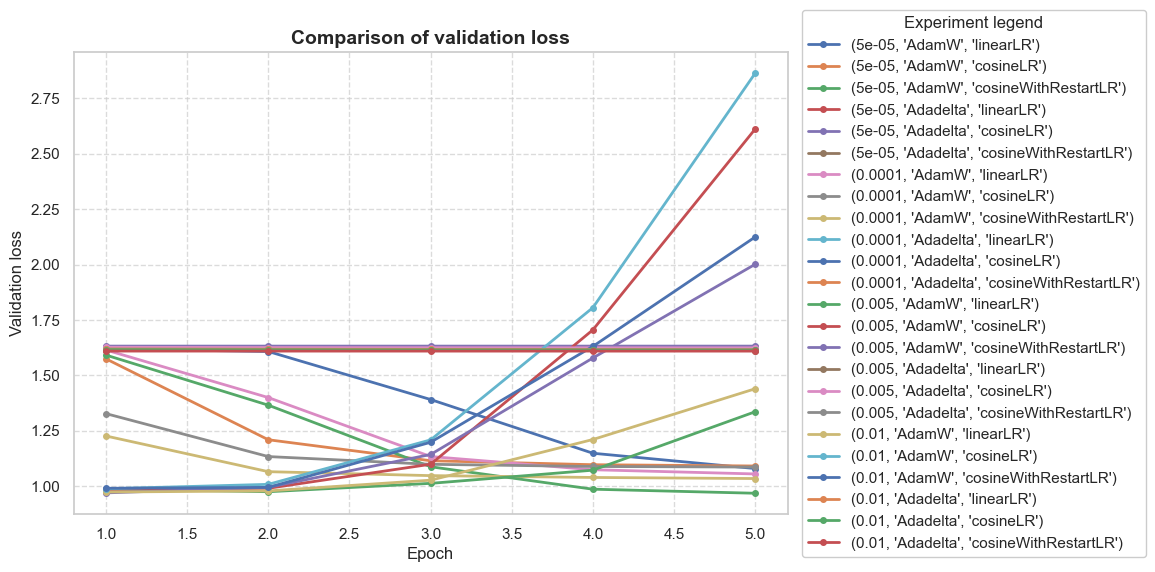

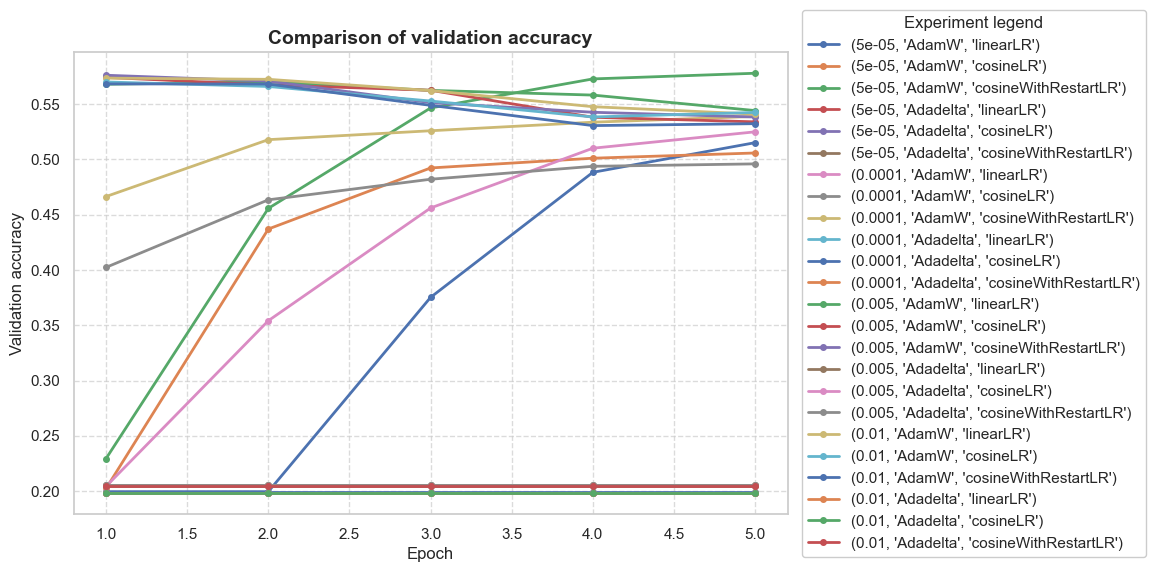

In [37]:
from itertools import product

all_tested_losses = {}
all_tested_acc = {}

num_epochs = 5

learning_rates = [5e-5, 1e-4, 5e-3, 1e-2]
optims = [("AdamW", torch.optim.AdamW), ("Adadelta", torch.optim.Adadelta)]
schedulers = [("linearLR", torch.optim.lr_scheduler.LinearLR), ("cosineLR", torch.optim.lr_scheduler.CosineAnnealingLR), ("cosineWithRestartLR", torch.optim.lr_scheduler.CosineAnnealingWarmRestarts)]

for params in product(learning_rates, optims, schedulers):
    lr, optim, scheduler = params
    optim_alias, optimizer = optim
    scheduler_alias, lr_scheduler = scheduler

    best_model = RatingClassifierExtendedV2(vocab_size, labels_num)
    best_model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optimizer(best_model.parameters(), lr=lr, weight_decay=1e-5)
    if scheduler_alias == "linearLR":
        lr_scheduler = lr_scheduler(optimizer, total_iters=num_epochs)
    elif scheduler_alias == "cosineLR":
        lr_scheduler = lr_scheduler(optimizer, T_max=num_epochs, eta_min=1e-5)
    else:
        lr_scheduler = lr_scheduler(optimizer, T_0=1, eta_min=1e-5)

    print("Testing:\n")
    print(best_model)
    print(optimizer)
    print(f"{scheduler}\n")
        
    accumulated_loss, accumulated_acc = train(best_model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
    all_tested_losses[(lr, optim_alias, scheduler_alias)] = accumulated_loss
    all_tested_acc[(lr, optim_alias, scheduler_alias)] = accumulated_acc


plot_comparison(all_tested_losses, title="Comparison of validation loss", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy", ylabel="Validation accuracy")


- best found config: optim - `AdamW`, lr - `lr=5e-5`, scheduler -`CosineAnnealingWarmRestarts` 

#### Check infulenece of epochs number on loss and accuracy - goal is to find margin where model doesn't learn anymore or can overfit 

- used best hiperparams + training params found in previous step (optimizer, scheduler, lr) 

In [41]:
all_tested_losses = {}
all_tested_acc = {}

print("Checking epochs number influence on training:\n")

model = RatingClassifierExtendedV2(vocab_size, labels_num)
model.to(device)
    
num_epochs = 200
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, eta_min=1e-5)

print(model)
print(optimizer)
print(lr_scheduler)
    
accumulated_loss, accumulated_acc = train(model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
all_tested_losses[(lr, optim_alias, scheduler_alias)] = accumulated_loss
all_tested_acc[(lr, optim_alias, scheduler_alias)] = accumulated_acc

Checking epochs number influence on training:

RatingClassifierExtendedV2(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 5e-05
    lr: 5e-05
    maximize: False
    weight_decay:

100%|██████████| 305/305 [00:04<00:00, 68.27it/s]


(Epoch 1/[train]) Loss:	1.616   Accuracy: 0.197   lr: 5e-05


100%|██████████| 77/77 [00:00<00:00, 102.50it/s]


(Epoch 1/[val]) Loss:	1.602   Accuracy: 0.205   lr: 5e-05


...

(Epoch 199/[val]) Loss:	6.727   Accuracy: 0.500   lr: 1.3819660112501054e-05


100%|██████████| 305/305 [00:03<00:00, 90.30it/s]


(Epoch 200/[train]) Loss:	0.020   Accuracy: 0.995   lr: 1.097886967409693e-05


100%|██████████| 77/77 [00:00<00:00, 160.49it/s]

(Epoch 200/[val]) Loss:	6.743   Accuracy: 0.500   lr: 1.097886967409693e-05


/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_38679/828334386.py:8: MatplotlibDeprecationWarning: Passing label as a length 3 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)


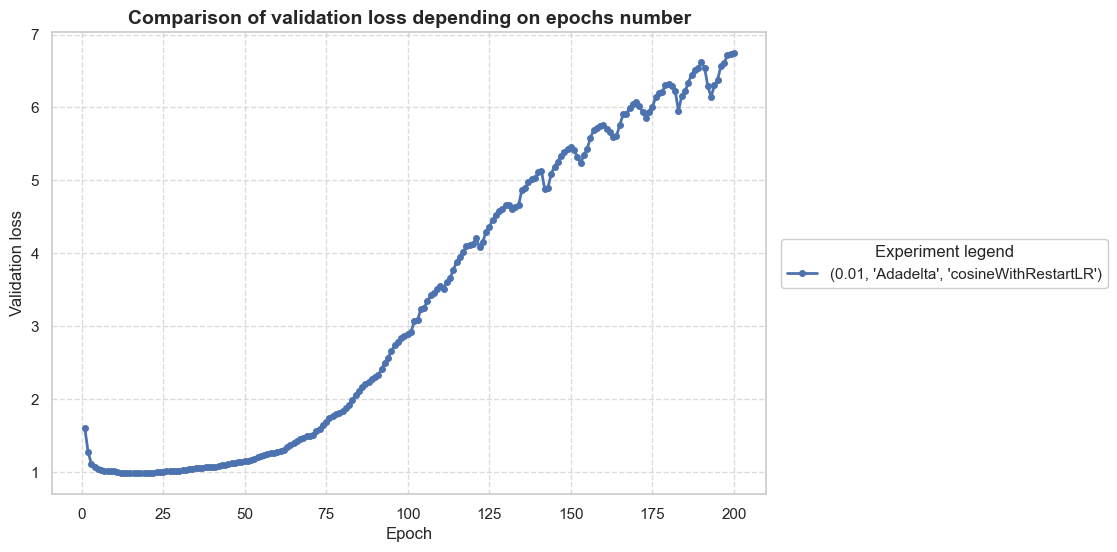

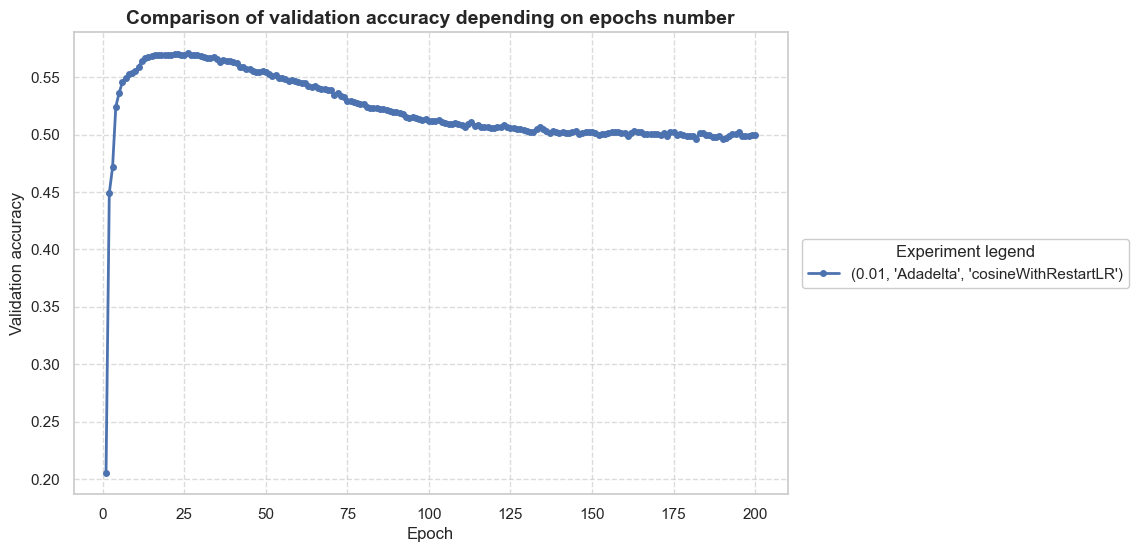

In [42]:
plot_comparison(all_tested_losses, title="Comparison of validation loss depending on epochs number", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy depending on epochs number", ylabel="Validation accuracy")

- optimal number of epochs for selected model, hiperparams, training params: circa `20 epochs`

## Final model

### Test Model with best eval acc-loss ratio

In [ ]:
# vocab_size = 10000

# vectorizer = TfidfVectorizer(
#     max_features=vocab_size,
#     lowercase=True,
#     analyzer="word",
#     ngram_range=(1, 3),
#     stop_words="english"
# )

# train_features = vectorizer.fit_transform(train_dataset["text"])

# val_features = vectorizer.transform(val_dataset["text"])
# test_features = vectorizer.transform(test_dataset["text"])


# datasets = {
#     'train': make_dataset(train_features, train_dataset['label']),
#     'val': make_dataset(val_features, val_dataset['label']),
#     'test': make_dataset(test_features, test_dataset['label'])
# }

# batch_size = 256

# data_loaders = {stage: DataLoader(datasets[stage], shuffle=stage=="train", num_workers=0, batch_size=batch_size) for stage in datasets}

In [43]:
model = RatingClassifierExtendedV2(vocab_size, labels_num)
model.to(device)

num_epochs = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-5)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, eta_min=1e-5)

print(model)
print(optimizer)
print(lr_scheduler)
    
accumulated_loss, accumulated_acc = train(model, data_loaders, criterion, optimizer, lr_scheduler, num_epochs)
all_tested_losses[(lr, optim_alias, scheduler_alias)] = accumulated_loss
all_tested_acc[(lr, optim_alias, scheduler_alias)] = accumulated_acc

RatingClassifierExtendedV2(
  (feature_extractor): Sequential(
    (0): Linear(in_features=10000, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): LeakyReLU(negative_slope=0.01)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): LeakyReLU(negative_slope=0.01)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (linear): Linear(in_features=16, out_features=5, bias=True)
)
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 5e-05
    lr: 5e-05
    maximize: False
    weight_decay: 1e-05
)


100%|██████████| 305/305 [00:04<00:00, 66.06it/s]


(Epoch 1/[train]) Loss:	1.610   Accuracy: 0.202   lr: 5e-05


100%|██████████| 77/77 [00:00<00:00, 104.46it/s]


(Epoch 1/[val]) Loss:	1.590   Accuracy: 0.202   lr: 5e-05


...

(Epoch 19/[val]) Loss:	1.017   Accuracy: 0.556   lr: 1.3819660112501054e-05


100%|██████████| 305/305 [00:03<00:00, 79.70it/s]


(Epoch 20/[train]) Loss:	0.914   Accuracy: 0.609   lr: 1.097886967409693e-05


100%|██████████| 77/77 [00:00<00:00, 100.74it/s]

(Epoch 20/[val]) Loss:	1.016   Accuracy: 0.557   lr: 1.097886967409693e-05


/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_38679/828334386.py:8: MatplotlibDeprecationWarning: Passing label as a length 3 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(epochs, metrics_val, label=model_name, linewidth=2, marker='o', markersize=4)


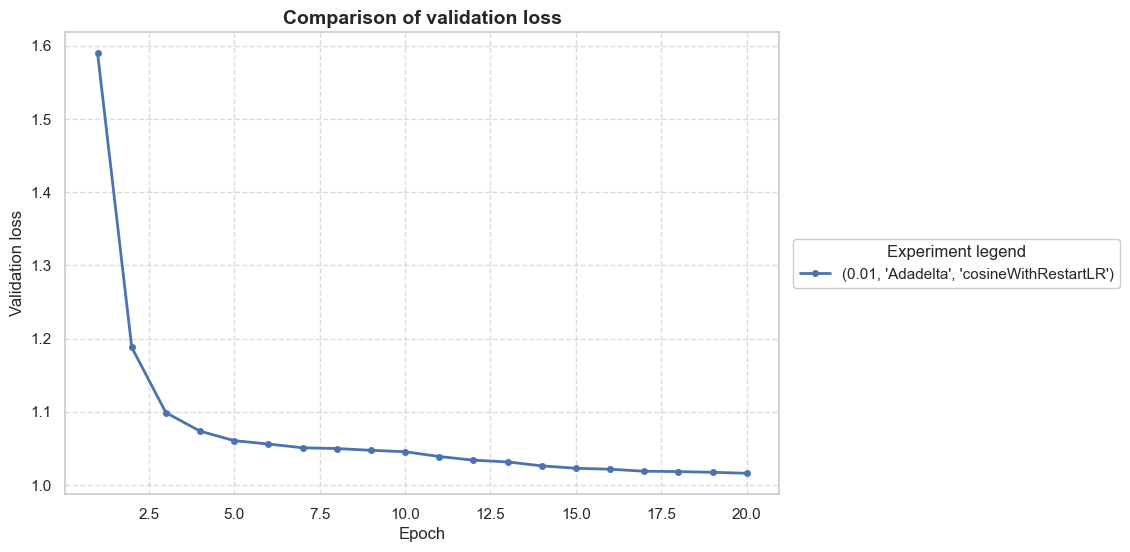

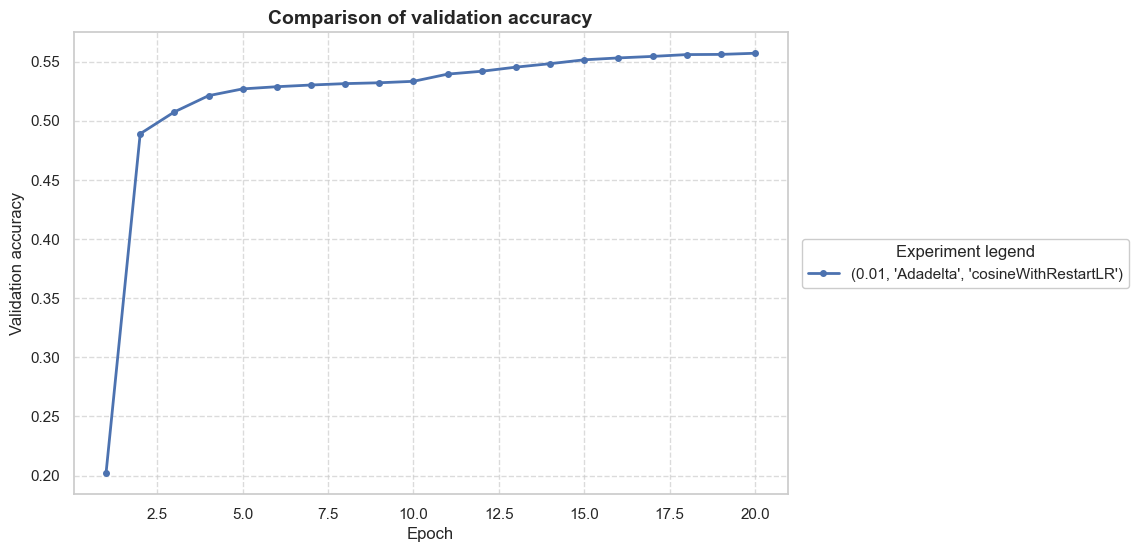

In [44]:
plot_comparison(all_tested_losses, title="Comparison of validation loss", ylabel="Validation loss")
plot_comparison(all_tested_acc, title="Comparison of validation accuracy", ylabel="Validation accuracy")

#### Test final model on test dataset

100%|██████████| 30/30 [00:00<00:00, 78.38it/s]


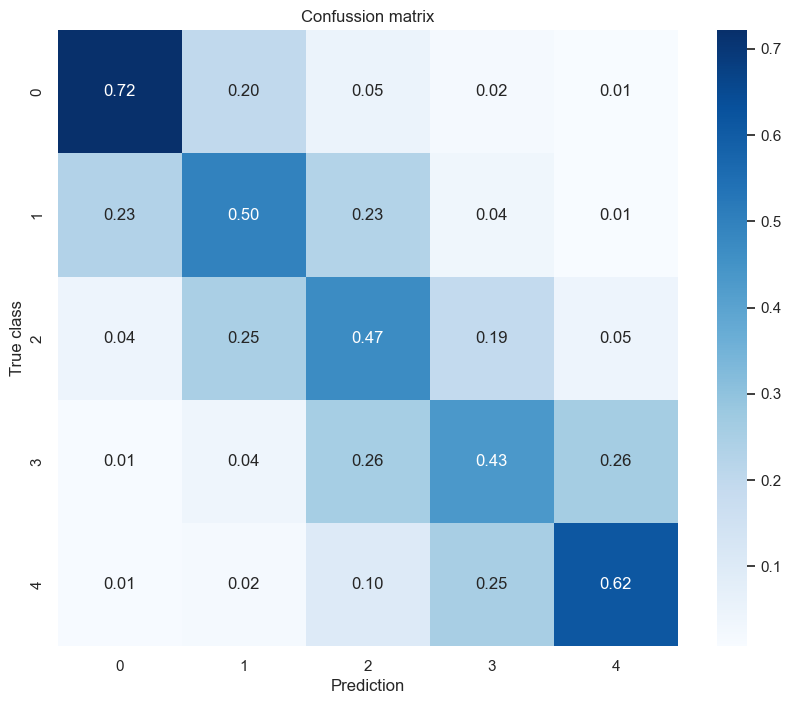

In [45]:
logits_l = []
preds_l = []
targets_l = []
input_l = []

model.eval()
with torch.inference_mode():
    for X_batch, target in tqdm(data_loaders['test']):
        X_batch, target = X_batch.to(device), target.to(device)
        logits = model(X_batch)
        _, preds = torch.max(logits, dim=-1)
        preds_l.append(preds.cpu())
        logits_l.append(logits.cpu())
        targets_l.append(target.cpu())
        input_l.append(X_batch.cpu())

all_logits = torch.cat(logits_l, dim=0)
all_preds = torch.cat(preds_l, dim=0)
all_targets = torch.cat(targets_l, dim=0)
all_input = torch.cat(input_l, dim=0)

plot_confusion_matrix(all_targets.numpy(), all_preds.numpy())

#### Save final model

In [46]:
torch.save(model.state_dict(), 'my_best_model_weights.pth')